In [4]:
# from agent.graph import agent_executor
from agent.graph import agent

input_variables=[] input_types={} partial_variables={'graph_schema': 'Node properties:\nAuthor {Institution: FLOAT, communityId: INTEGER, id: INTEGER, name: STRING}\nArticle {title: STRING, year: INTEGER, id: INTEGER, rebuilt_abstract: STRING, doi: STRING, publisher: STRING}\nVenue {id: INTEGER, name: STRING}\nKeyword {name: STRING, id: STRING, communityId: INTEGER}\nInstitution {name: STRING, id: STRING}\nRelationship properties:\n\nThe relationships:\n(:Author)-[:WORKS_AT]->(:Institution)\n(:Article)-[:HAS_KEYWORD]->(:Keyword)\n(:Article)-[:WRITTEN_BY]->(:Author)\n(:Article)-[:REFERENCES]->(:Article)\n(:Article)-[:PUBLISHED_IN]->(:Venue)'} messages=[SystemMessagePromptTemplate(prompt=PromptTemplate(input_variables=['graph_schema'], input_types={}, partial_variables={}, template='You are an expert graph database assistant. Your job is to help users query an academic corpus graph database using the available tools.\n\nDatabase Schema:\n{graph_schema}\n\nINSTRUCTIONS:\n- You MUST use th

In [5]:
tool_call = agent.invoke({"input": "Is there any scientist named Lionel. List the tools you need for this task"})
tool_call

TooManyRequestsResponseError: Rate limit exceeded: free-models-per-day. Add 10 credits to unlock 1000 free model requests per day

In [7]:

tool_call = agent.invoke({
    "messages": [("user", "List all the tools available to you and their descriptions.")]
})

print(tool_call["messages"][-1].content)


Here are all the available tools and their descriptions:

1. **get_researcher_basic_info**
   - Accepts either a researcher's name (`who`) or ID (`id`)
   - If given a name: returns up to 5 people with that name, their IDs, and institutions
   - If given an ID: returns specific person information

2. **get_researcher_works_info**
   - Accepts an author ID as parameter
   - Returns the author's works in decreasing order of citation number

3. **get_h_index_of**
   - Accepts an author ID as parameter
   - Returns the author's h-index

4. **get_alike**
   - Accepts an author ID as parameter
   - Returns other authors in the same research community

5. **get_path**
   - Accepts two author IDs (`id1` and `id2`)
   - Returns the shortest path between them in the collaboration network

These tools allow you to query information about researchers, their works, citation metrics, research communities, and collaboration paths in the academic corpus graph database.


In [10]:
from langchain_openai import ChatOpenAI
ai_api_url = os.getenv("AI_API_URL", "http://localhost:12434/engines/v1")

llm = ChatOpenAI(
    base_url=ai_api_url,
    api_key="docker",
    model='huggingface.co/bartowski/llama-3-groq-8b-tool-use-gguf:Q6_K_L',
    temperature=0,
)

In [ ]:
from langchain.agents import create_agent
agent = create_agent(
    llm,
    tools=[get_alike, get_path],
    # context_schema=UserContext,
    # checkpointer=InMemorySaver(),
    system_prompt="You are a financial assistant.",
)

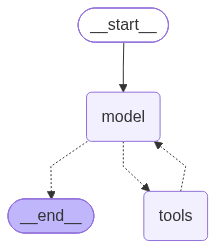

In [6]:
agent